In [26]:
%pip install imblearn

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    PrecisionRecallDisplay,
    RocCurveDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

Note: you may need to restart the kernel to use updated packages.


In [27]:
FILE_PATH = Path("..", "data", "processed", "fraud_data.csv")
TARGET_COL = "is_fraud"
TEST_SIZE = 0.2
RANDOM_STATE = 42

# Load and Examine Data

In [ ]:
df = pd.read_csv(FILE_PATH)
print(f"Data shape: {df.shape}")

In [ ]:
df.head()

,transaction_id,date,amount,use_chip,merchant_state,is_fraud,user_id,current_age,retirement_age,gender,...,card_brand,card_type,has_chip,num_cards_issued,credit_limit,is_prepaid,hour_of_day,day_of_week,month,year
0,7477483,2010-01-01 13:10:00,33.96,swipe,ME,0,0,33,69,Male,...,Mastercard,Credit,1,1,17600.0,0,13,6,1,2010
1,7478861,2010-01-01 19:39:00,7.78,swipe,ME,0,0,33,69,Male,...,Mastercard,Credit,1,1,17600.0,0,19,6,1,2010
2,7479264,2010-01-01 22:13:00,65.86,swipe,ME,0,0,33,69,Male,...,Mastercard,Credit,1,1,17600.0,0,22,6,1,2010
3,7481226,2010-01-02 13:08:00,55.85,swipe,ME,0,0,33,69,Male,...,Mastercard,Credit,1,1,17600.0,0,13,7,1,2010
4,7485861,2010-01-03 15:44:00,1.37,swipe,ME,0,0,33,69,Male,...,Mastercard,Credit,1,1,17600.0,0,15,1,1,2010


In [ ]:
# Check for missing values
df.isnull().sum()

transaction_id      0
date                0
amount              0
use_chip            0
merchant_state      0
is_fraud            0
user_id             0
current_age         0
retirement_age      0
gender              0
credit_score        0
num_credit_cards    0
yearly_income       0
total_debt          0
card_id             0
card_brand          0
card_type           0
has_chip            0
num_cards_issued    0
credit_limit        0
is_prepaid          0
hour_of_day         0
day_of_week         0
month               0
year                0
dtype: int64

In [ ]:
# Taregt variable distribution
df[TARGET_COL].value_counts()

is_fraud
0    11651969
1        1234
Name: count, dtype: int64

# Prepare Features

In [ ]:
cols_to_drop = ["transaction_id", "date", "user_id", "card_id"]
features = [col for col in df.columns if col != TARGET_COL and col not in cols_to_drop]

X = df[features]
y = df[TARGET_COL]

categorical_feats = X.select_dtypes(include=["object", "category"]).columns
numerical_feats = X.select_dtypes(include=np.number).columns

print(f"Using {len(features)} features.")
print(f"Categorical features: {list(categorical_feats)}")
print(f"Numerical features: {list(numerical_feats)}")

Using 20 features.
Categorical features: ['use_chip', 'merchant_state', 'gender', 'card_brand', 'card_type']
Numerical features: ['amount', 'current_age', 'retirement_age', 'credit_score', 'num_credit_cards', 'yearly_income', 'total_debt', 'has_chip', 'num_cards_issued', 'credit_limit', 'is_prepaid', 'hour_of_day', 'day_of_week', 'month', 'year']


## Train/Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y  # Proportional representation of `is_fraud` classes between train and test set
)
print(f"Training set shape: {X_train.shape}, Test set shape: {X_test.shape}")

Training set shape: (9322562, 20), Test set shape: (2330641, 20)


## Set Up Pipeline

In [ ]:
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, numerical_feats),
        ("cat", cat_transformer, categorical_feats)
    ],
    remainder="passthrough"
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        solver="liblinear"
    ))
])

# Train Model

In [ ]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  Index(['amount', 'current_age', 'retirement_age', 'credit_score',
       'num_credit_cards', 'yearly_income', 'total_debt', 'has_chip',
       'num_cards_issued', 'credit_limit', 'is_prepaid', 'hour_of_day',
       'day_of_week', 'month', 'year'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  Index(['use_chip', 'merchant_state', 'gender', 'card_brand', 'card_type'], dtype='object'))])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', random_state=42,
                                    solver='liblinear'))])

# Evaluate Model

In [ ]:
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

In [ ]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.78      0.88   2330394
           1       0.00      0.61      0.00       247

    accuracy                           0.78   2330641
   macro avg       0.50      0.70      0.44   2330641
weighted avg       1.00      0.78      0.88   2330641



## Plot Confusion Matrix


Confusion Matrix:


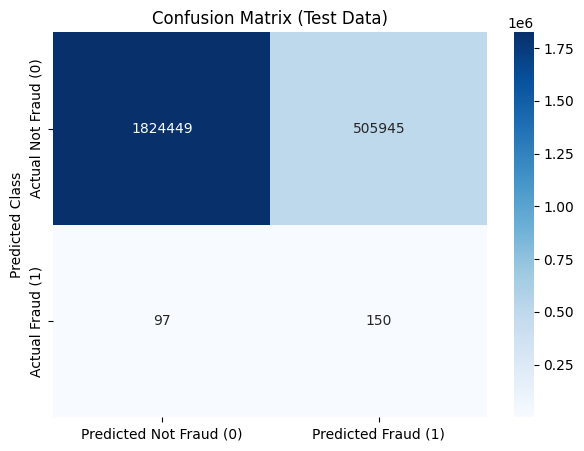

In [ ]:
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Not Fraud (0)", "Predicted Fraud (1)"],
    yticklabels=["Actual Not Fraud (0)", "Actual Fraud (1)"]
)
plt.ylabel("Actual Class")
plt.ylabel("Predicted Class")
plt.title("Confusion Matrix (Test Data)")
plt.show()

## Precision-Recall Curve

Shows the trade-off between Precision and Recall for different thresholds.

A model closer to the top-right corner is better. Higher AUC-PR is better.

<Figure size 800x600 with 0 Axes>

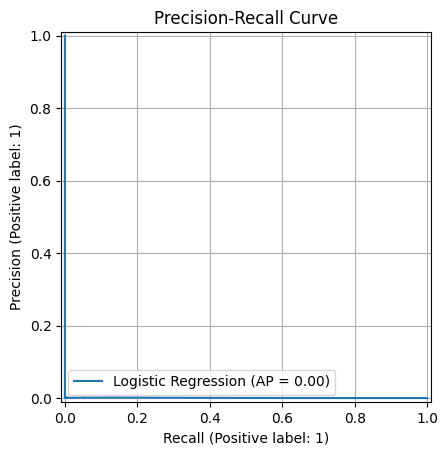

Area Under PR Curve (AUC-PR): 0.0006


In [ ]:
plt.figure(figsize=(8, 6))
pr_display = PrecisionRecallDisplay.from_predictions(
    y_test, y_pred_proba, name="Logistic Regression"
)
plt.title("Precision-Recall Curve")
plt.grid(True)
plt.show()
print(f"Area Under PR Curve (AUC-PR): {pr_display.average_precision:.4f}")

## ROC Curve

Shows the trade-off between True Postive Rate (Recall) and False Positive Rate.

A model closer to the top-left corner is better. Higher ROC AUC is better.

<Figure size 800x600 with 0 Axes>

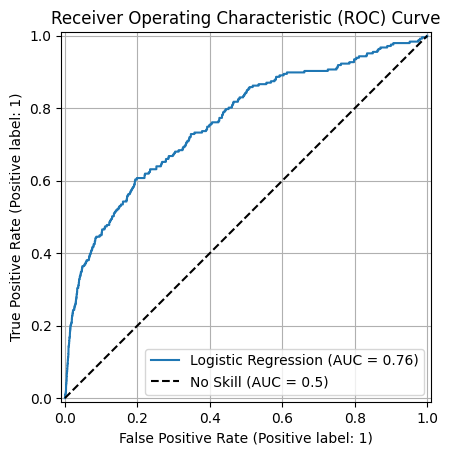

Area Under ROC Curve (ROC AUC): 0.7613


In [ ]:
plt.figure(figsize=(8, 6))
roc_display = RocCurveDisplay.from_predictions(y_test, y_pred_proba, name="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--", label="No Skill (AUC = 0.5)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.grid(True)
plt.legend()
plt.show()
print(f"Area Under ROC Curve (ROC AUC): {roc_display.roc_auc:.4f}")

## Predicted Probability Distribution

Ideally, the two distributions should be well-separated. A large overlap indicates the model struggles to distinguish between classes.

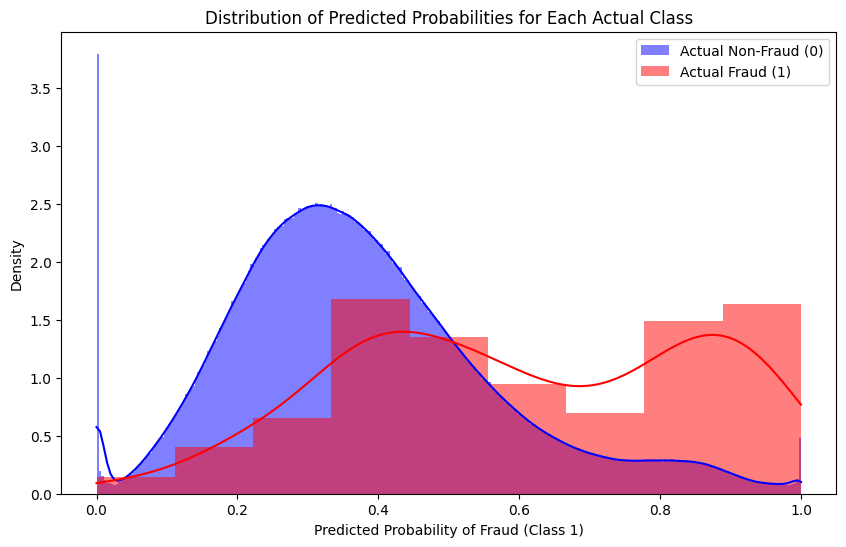

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(
    y_pred_proba[y_test == 0],
    color="blue",
    kde=True,
    stat="density",
    linewidth=0,label="Actual Non-Fraud (0)"
)
sns.histplot(
    y_pred_proba[y_test == 1],
    color="red",
    kde=True,
    stat="density",
    linewidth=0,
    label="Actual Fraud (1)"
)
plt.title("Distribution of Predicted Probabilities for Each Actual Class")
plt.xlabel("Predicted Probability of Fraud (Class 1)")
plt.ylabel("Density")
plt.legend()
plt.show()

## Feature Importance

Positive coefficients increase the log-odds (and thus probability) of fraud. Negative coefficients decrease the log-odds of fraud. Features with larger absolute coefficients have a stronger influence on the prediction.

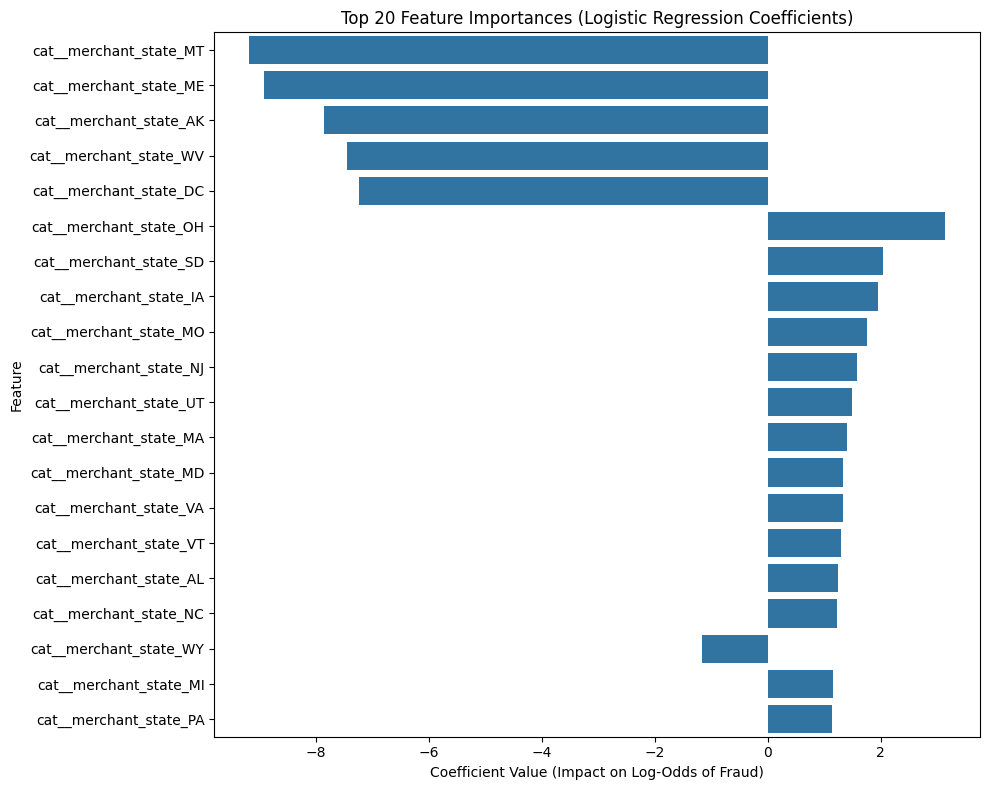

In [ ]:
classifier = model.named_steps["classifier"]
preprocessor = model.named_steps["preprocessor"]
feature_names = preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]
importance_df = pd.DataFrame({"Feature": feature_names, "Coefficient": coefficients})
importance_df["Abs_Coefficient"] = importance_df["Coefficient"].abs()
importance_df = importance_df.sort_values(by="Abs_Coefficient", ascending=False)

N = 20
plt.figure(figsize=(10, N / 2.5))
sns.barplot(x="Coefficient", y="Feature", data=importance_df.head(N))
plt.title(f"Top {N} Feature Importances (Logistic Regression Coefficients)")
plt.xlabel("Coefficient Value (Impact on Log-Odds of Fraud)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Results

- `ROC AUC = 0.7613`
    - This measures the model's ability to distinguish between the positive (fraud) and negative (non-fraud) classes across all probability thresholds.
    - A score of 0.5 is random chance, and 1.0 is perfect.
    - **0.76 suggests our model has a moderate ability to differentiate between fraud and non-fraud.**
    - However, for an imbalanced dataset, ROC AUC can be overly optimistic bcause correctly identifying the majority class (non-fraud) influences the score.
- `AUC-PR = 0.0006`:
    - This measures the Area Under the Precision-Recall Curve. It's more informative than ROC AUC for highly imbalanced datasets.
    - The baseline for AUC-PR is the fraction of the positive samples in the dataset (if 0.1% of transactions are fraud, the baseline is ~0.001).
    - **An AUC of 0.0006 is extremely low.** The model is struggling to achieve good Precision when trying to identify the positive (fraud) class.
        - Even if the model can increase Recall (catch more fraud) by lowering the decision threshold, the Precision drops drastically. To catch *some* fraud, the model flags a *very large* number of legitimate transactions as fraudulent, meaning there will be many False Positive. 

Overall, the model performs very poorly on the task of identifying fraud without generating an overwhelming number of false positives. The model isn't good at finding rare fraud cases with high confidence. We should focus on techniques specifically designed to improve performance on the minority class.

# Improving the Model

## Deeper Exploration of Features
### Distributions of Numerical Features

c:\Users\Yogin\Desktop\Dev10_Capstone\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


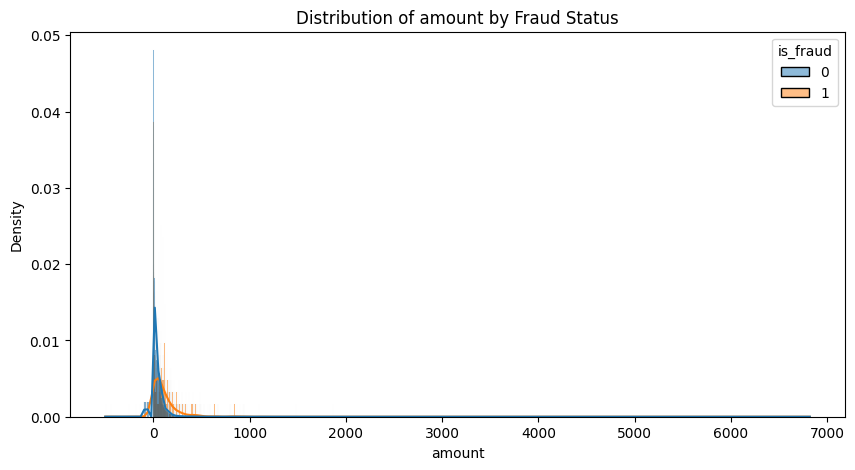

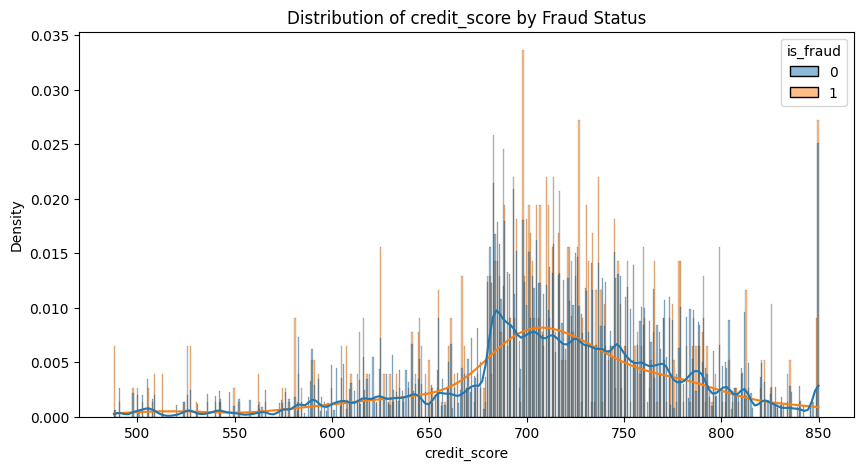

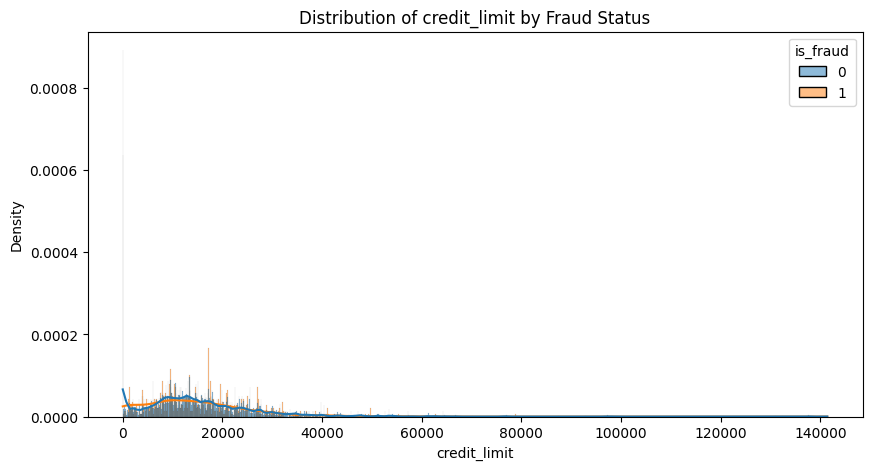

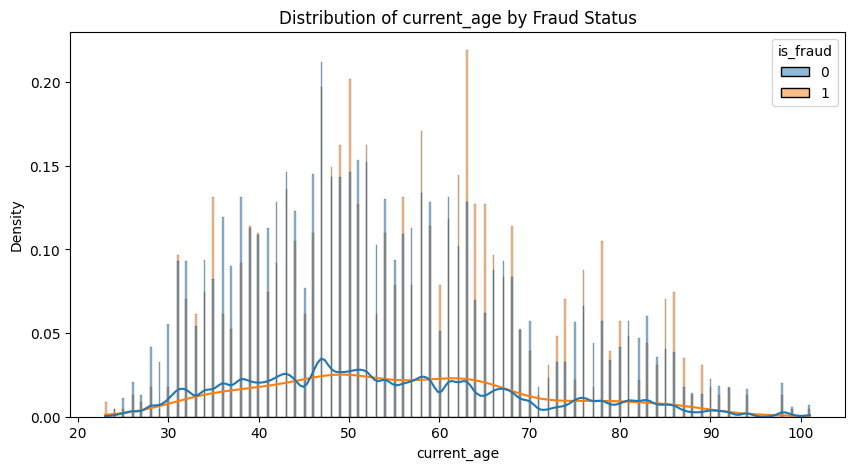

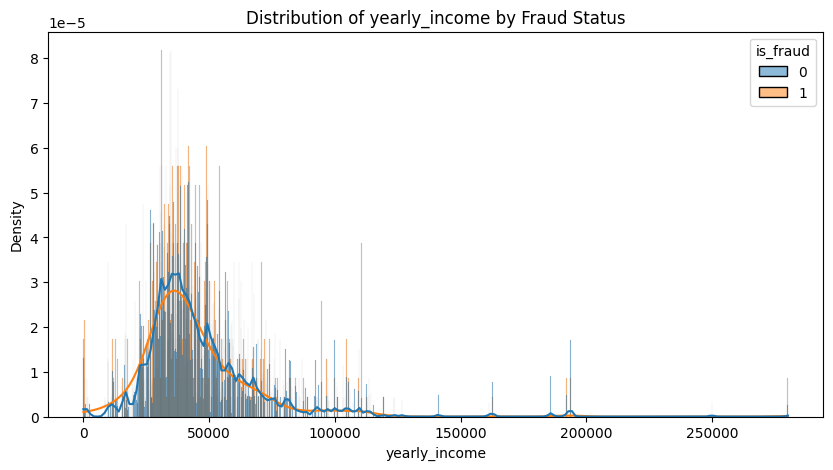

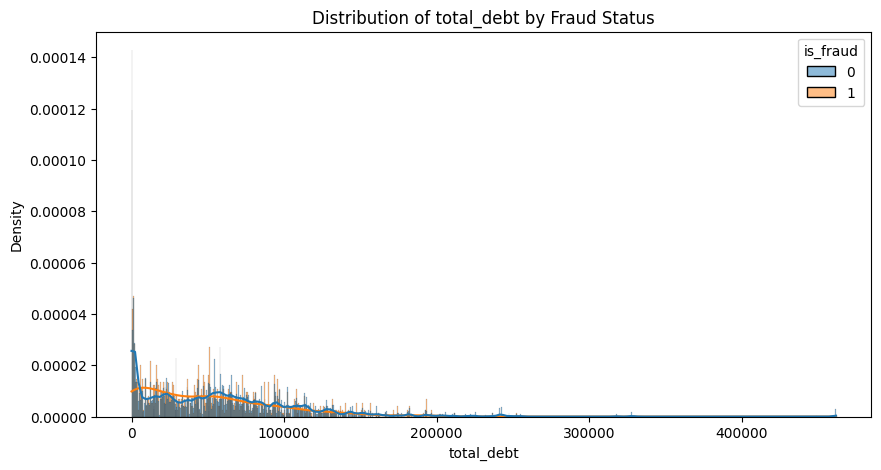

In [ ]:
numerical_plot = ["amount", "credit_score", "credit_limit", "current_age", "yearly_income", "total_debt"]
for col in numerical_plot:
    plt.figure(figsize=(10, 5))
    sns.histplot(data=df, x=col, hue=TARGET_COL, kde=True, stat="density", common_norm=False)
    plt.title(f"Distribution of {col} by Fraud Status")
    plt.show()

### Distributions of Categorical Features


Fraud Rate by use_chip:
use_chip
swipe    0.000122
chip     0.000082
Name: is_fraud, dtype: float64


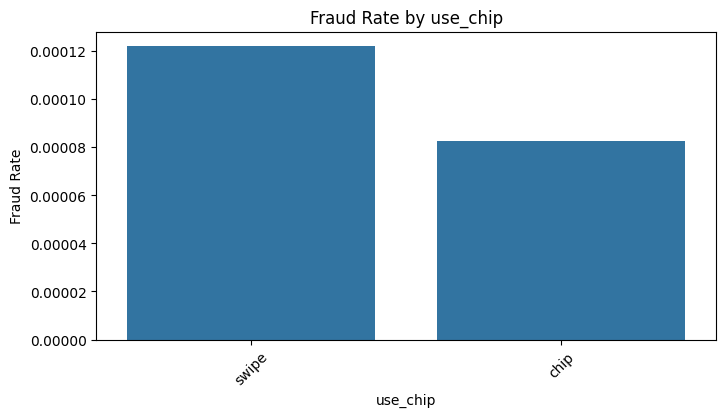


Fraud Rate by card_type:
card_type
Credit    0.000106
Debit     0.000106
Name: is_fraud, dtype: float64


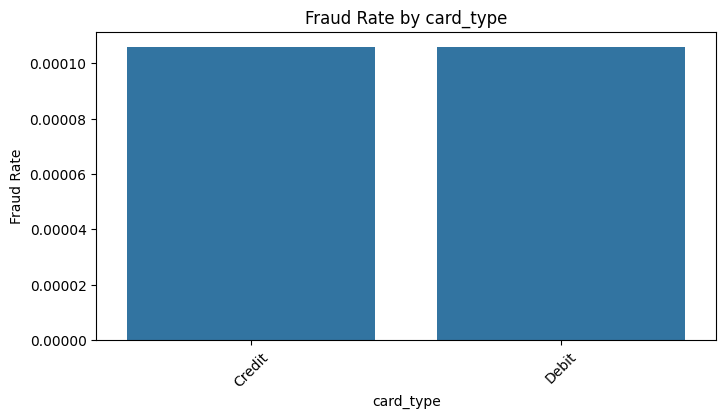


Fraud Rate by card_brand:
card_brand
Mastercard    0.000112
Discover      0.000107
Visa          0.000101
Amex          0.000088
Name: is_fraud, dtype: float64


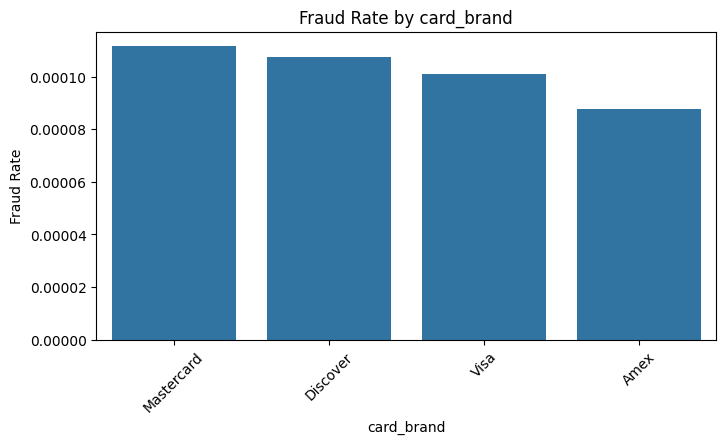


Fraud Rate by gender:
gender
Female    0.000112
Male      0.000099
Name: is_fraud, dtype: float64


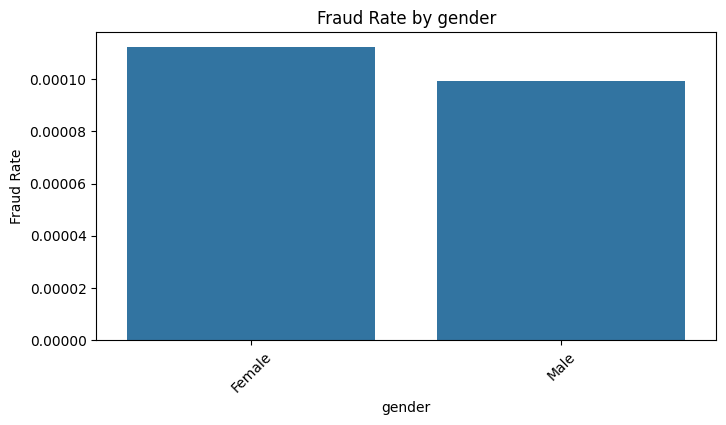

In [ ]:
categorical_plot = ["use_chip", "card_type", "card_brand", "gender"]
for col in categorical_plot:
    fraud_rate = df.groupby(col)[TARGET_COL].mean().sort_values(ascending=False)
    print(f"\nFraud Rate by {col}:\n{fraud_rate}")
    plt.figure(figsize=(8, 4))
    sns.barplot(x=fraud_rate.index, y=fraud_rate.values)
    plt.title(f"Fraud Rate by {col}")
    plt.ylabel("Fraud Rate")
    plt.xticks(rotation=45)
    plt.show()

### Fraud Rates at Different Times


Fraud Rate by hour_of_day:
hour_of_day
0     0.000000
1     0.000000
2     0.000000
3     0.000033
4     0.000044
5     0.000083
6     0.000039
7     0.000031
8     0.000049
9     0.000111
10    0.000219
11    0.000183
12    0.000184
13    0.000210
14    0.000126
15    0.000111
16    0.000113
17    0.000117
18    0.000076
19    0.000088
20    0.000019
21    0.000013
22    0.000003
23    0.000000
Name: is_fraud, dtype: float64


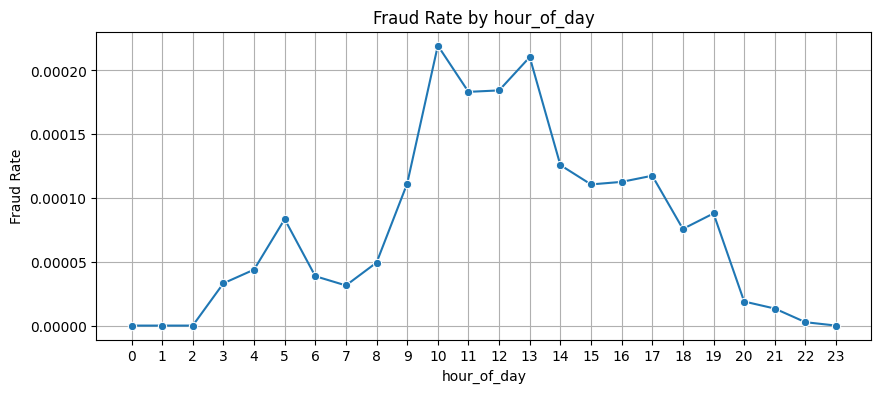


Fraud Rate by day_of_week:
day_of_week
1    0.000191
2    0.000065
3    0.000125
4    0.000060
5    0.000098
6    0.000095
7    0.000108
Name: is_fraud, dtype: float64


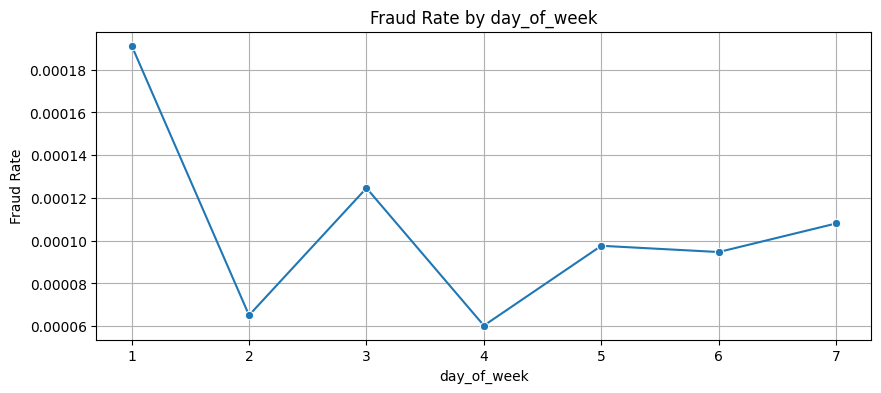

In [ ]:
time_features = ["hour_of_day", "day_of_week"]
for col in time_features:
    fraud_rate_time = df.groupby(col)[TARGET_COL].mean()
    print(f"\nFraud Rate by {col}:\n{fraud_rate_time}")
    plt.figure(figsize=(10, 4))
    sns.lineplot(x=fraud_rate_time.index, y=fraud_rate_time.values, marker="o")
    plt.title(f"Fraud Rate by {col}")
    plt.ylabel("Fraud Rate")
    plt.xticks(fraud_rate_time.index)
    plt.grid(True)
    plt.show()

### Results

1. Most of the numerical features overlap. Numerical features like `amount`, `credit_score`, etc., don't have vastly different distributions for fradulent vs. non-fradulent transactions on their own (with a slight exception to `amount`). This may suggest why a linear model like Logistic Regression struggled. The separation isn't a simple linear boundary based on these raw features. Non-linear models or more features are needed.

2. The fraud rates across the categroies like `use_chip`, `card_type`, `card_brand`, and `gender` are very similar. For example, Credit vs. Debit card type have identical rates. There are tiny differences between swipe vs. chip, and different card brands. These features alone, however, are likely weak predictors.

3. The time features are more informative.  
    - Fraud rates are near zero late at night/very early in the morning and peak late morning/early afternoon (10 AM-1 PM), and decrease in the evening.
    - Day 1 (Monday) has a noticeably higher rate.

Therefore, we should try non-linear models like Random Forest or XGBoost. We will also try feature engineering to add more context.

## Simple Feature Engineering

In [ ]:
df["amount_to_limit_ratio"] = df["amount"] / (df["credit_limit"] + 1e-6)
df["date"] = pd.to_datetime(df["date"])

# Time since last transaction
df = df.sort_values(by=["user_id", "card_id", "date"], ascending=True)
df["time_since_last_txn_sec"] = df.groupby(["user_id", "card_id"])["date"].diff().dt.total_seconds()
df["time_since_last_txn_sec"] = df["time_since_last_txn_sec"].fillna(0)

# Transaction frequency
df = df.sort_values(by=["user_id", "date"], ascending=True)
df = df.reset_index(drop=True).reset_index().rename(columns={"index": "index_orig"})
df_indexed = df.set_index("date")
rolling_count = df_indexed.groupby("user_id").rolling("1h", closed="left")["index_orig"].count()
rolling_count.name = "txn_count_user_1h"
rolling_count_df = rolling_count.reset_index()

df = pd.merge(
    df,
    rolling_count_df[["date", "user_id", "txn_count_user_1h"]],
    on=["date", "user_id"],
    how="left"
)

df["txn_count_user_1h"] = df["txn_count_user_1h"].fillna(0)

df = df.drop(columns=["index_orig"])

cols_to_drop = ["transaction_id", "date", "user_id", "card_id"]
features = [col for col in df.columns if col != TARGET_COL and col not in cols_to_drop]

X = df[features]
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)
print(f"Training set shape: {X_train.shape}, Test set shape: {X_test.shape}")

numerical_feats = X_train.select_dtypes(include=np.number).columns
categorical_feats = X_train.select_dtypes(include=["object", "category"]).columns

print(f"\nNew numerical features: {list(numerical_feats)}")
print(f"New categorical features: {list(categorical_feats)}")

Training set shape: (9451397, 23), Test set shape: (2362850, 23)

New numerical features: ['amount', 'current_age', 'retirement_age', 'credit_score', 'num_credit_cards', 'yearly_income', 'total_debt', 'has_chip', 'num_cards_issued', 'credit_limit', 'is_prepaid', 'hour_of_day', 'day_of_week', 'month', 'year', 'amount_to_limit_ratio', 'time_since_last_txn_sec', 'txn_count_user_1h']
New categorical features: ['use_chip', 'merchant_state', 'gender', 'card_brand', 'card_type']


# Random Forest Model

In [ ]:
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, numerical_feats),
        ("cat", cat_transformer, categorical_feats)
    ],
    remainder="passthrough"
)

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1,
    ))
])

rf_pipeline.fit(X_train, y_train)

MemoryError: Unable to allocate 72.1 MiB for an array with shape (9451397,) and data type int64

# Evaluate Random Forest

In [ ]:
y_pred_rf = rf_pipeline.predict(X_test)
y_pred_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   2362602
           1       0.00      0.00      0.00       248

    accuracy                           1.00   2362850
   macro avg       0.50      0.50      0.50   2362850
weighted avg       1.00      1.00      1.00   2362850



## Confusion Matrix


Confusion Matrix:


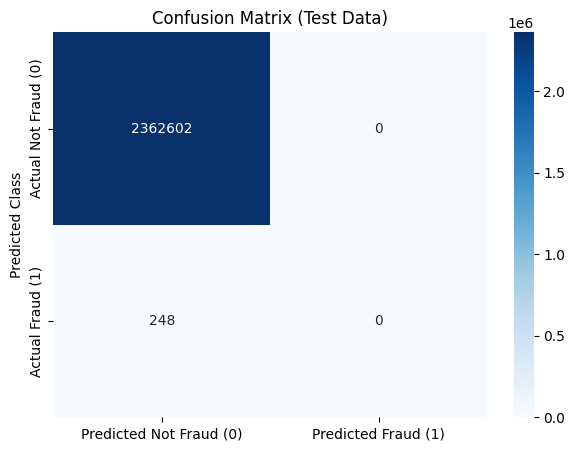

In [ ]:
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Not Fraud (0)", "Predicted Fraud (1)"],
    yticklabels=["Actual Not Fraud (0)", "Actual Fraud (1)"]
)
plt.ylabel("Actual Class")
plt.ylabel("Predicted Class")
plt.title("Confusion Matrix (Test Data)")
plt.show()

## Precision-Recall Curve

<Figure size 800x600 with 0 Axes>

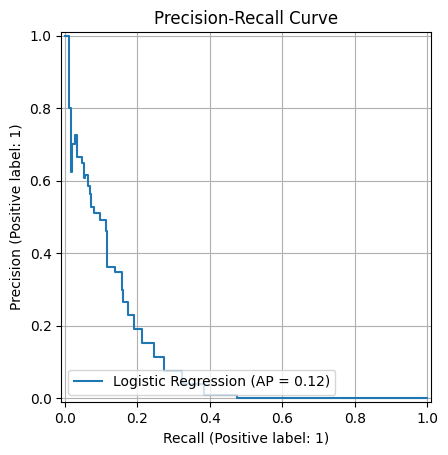

Area Under PR Curve (AUC-PR): 0.1163


In [ ]:
plt.figure(figsize=(8, 6))
pr_display = PrecisionRecallDisplay.from_predictions(
    y_test, y_pred_proba_rf, name="Logistic Regression"
)
plt.title("Precision-Recall Curve")
plt.grid(True)
plt.show()
print(f"Area Under PR Curve (AUC-PR): {pr_display.average_precision:.4f}")

## ROC Curve

<Figure size 800x600 with 0 Axes>

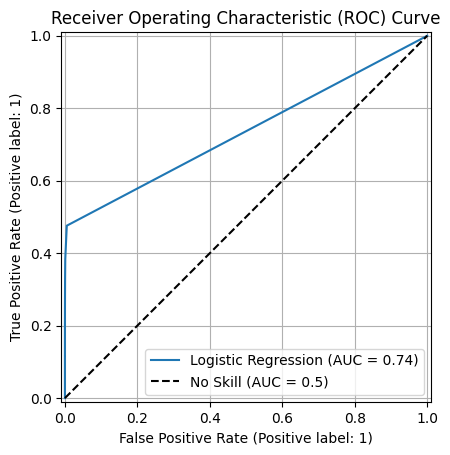

Area Under ROC Curve (ROC AUC): 0.7362


In [ ]:
plt.figure(figsize=(8, 6))
roc_display = RocCurveDisplay.from_predictions(y_test, y_pred_proba_rf, name="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--", label="No Skill (AUC = 0.5)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.grid(True)
plt.legend()
plt.show()
print(f"Area Under ROC Curve (ROC AUC): {roc_display.roc_auc:.4f}")

## Predicted Probability Distribution

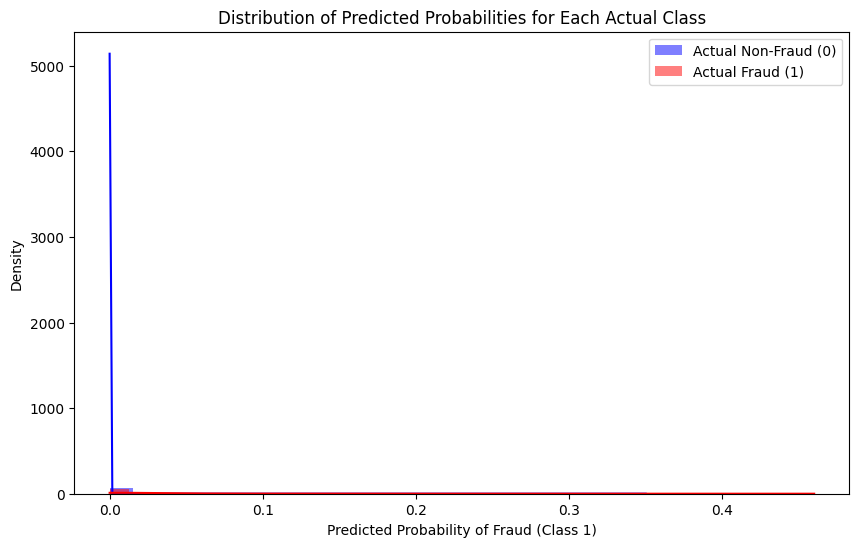

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(
    y_pred_proba_rf[y_test == 0],
    color="blue",
    kde=True,
    stat="density",
    linewidth=0,label="Actual Non-Fraud (0)"
)
sns.histplot(
    y_pred_proba_rf[y_test == 1],
    color="red",
    kde=True,
    stat="density",
    linewidth=0,
    label="Actual Fraud (1)"
)
plt.title("Distribution of Predicted Probabilities for Each Actual Class")
plt.xlabel("Predicted Probability of Fraud (Class 1)")
plt.ylabel("Density")
plt.legend()
plt.show()

# Results
- The Random Forest, despite `class_weight="balanced`, **failed to identify *any* of the actual fraud cases**.
- The AUC-PR improved to 0.1163.
- Random Forest also predicted nearly all zero probabilities.
- Random Forest fundamentally failed to learn differentiating pattern for the fraud class.

An alternative might be Logistic Regression + SMOTE.

# Logistic Regression + SMOTE

In [ ]:
lr_smote_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
    ("classifier", LogisticRegression(
        random_state=RANDOM_STATE,
        solver="liblinear",
        n_jobs=-1
    ))
])

lr_smote_pipeline.fit(X_train, y_train)

/Users/cdunning/Desktop/projects/shiv_project/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 10.
  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  Index(['amount', 'current_age', 'retirement_age', 'credit_score',
       'num_credit_cards', 'yearly_income', 'total_debt', 'has_chip',
       'num_cards_issued', 'credit_limit', 'is_prepaid', 'hour_of_day',
       'day_of_week', 'month', 'year', 'amount_to_limit_ratio',
       'time_since_last_txn_sec', 'txn_count_user_1h'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  Index(['use_chip', 'merchant_state', 'gender', 'card_brand', 'card_type'], dtype='object'))])),
                ('smote', SMOTE(random_state=42)),
                ('classifier',
                 LogisticRegression(n_jobs=-1, random_state=42,
                                    solver='liblinear'))])

# Evaluate Logistic Regression + SMOTE

In [ ]:
y_pred_lr_smote = lr_smote_pipeline.predict(X_test)
y_pred_proba_lr_smote = lr_smote_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_lr_smote, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      0.80      0.89   2362602
           1       0.00      0.60      0.00       248

    accuracy                           0.80   2362850
   macro avg       0.50      0.70      0.45   2362850
weighted avg       1.00      0.80      0.89   2362850



## Confusion Matrix


Confusion Matrix:


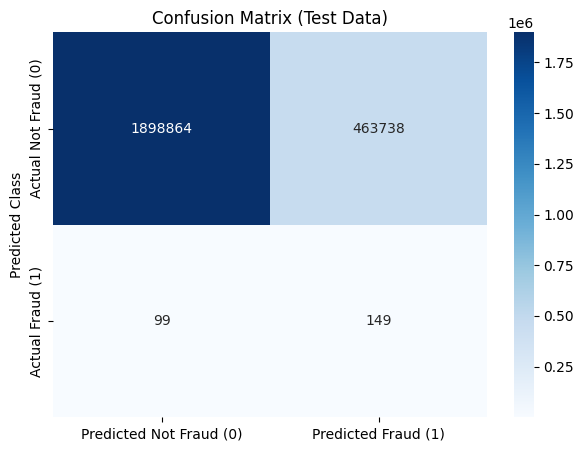

In [ ]:
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_lr_smote)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Not Fraud (0)", "Predicted Fraud (1)"],
    yticklabels=["Actual Not Fraud (0)", "Actual Fraud (1)"]
)
plt.ylabel("Actual Class")
plt.ylabel("Predicted Class")
plt.title("Confusion Matrix (Test Data)")
plt.show()

## Precision-Recall Curve

<Figure size 800x600 with 0 Axes>

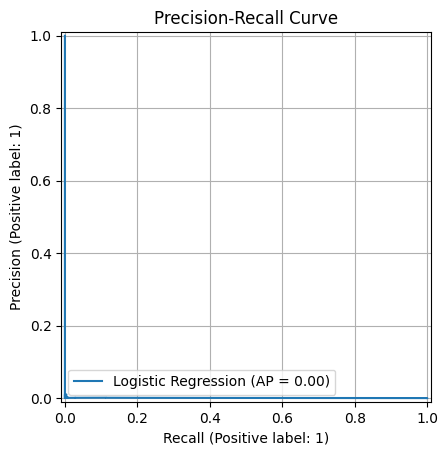

Area Under PR Curve (AUC-PR): 0.0005


In [ ]:
plt.figure(figsize=(8, 6))
pr_display = PrecisionRecallDisplay.from_predictions(
    y_test, y_pred_proba_lr_smote, name="Logistic Regression"
)
plt.title("Precision-Recall Curve")
plt.grid(True)
plt.show()
print(f"Area Under PR Curve (AUC-PR): {pr_display.average_precision:.4f}")

# ROC Curve

<Figure size 800x600 with 0 Axes>

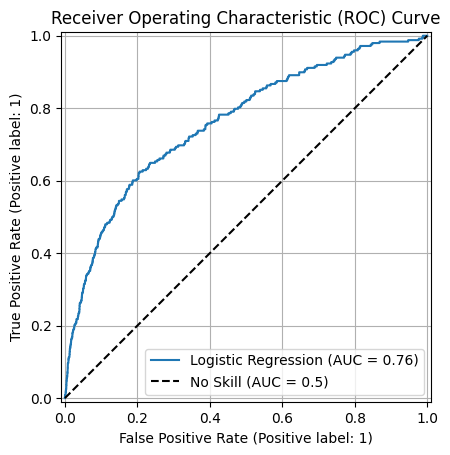

Area Under ROC Curve (ROC AUC): 0.7620


In [ ]:
plt.figure(figsize=(8, 6))
roc_display = RocCurveDisplay.from_predictions(y_test, y_pred_proba_lr_smote, name="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--", label="No Skill (AUC = 0.5)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.grid(True)
plt.legend()
plt.show()
print(f"Area Under ROC Curve (ROC AUC): {roc_display.roc_auc:.4f}")

## Predicted Probability Distribution

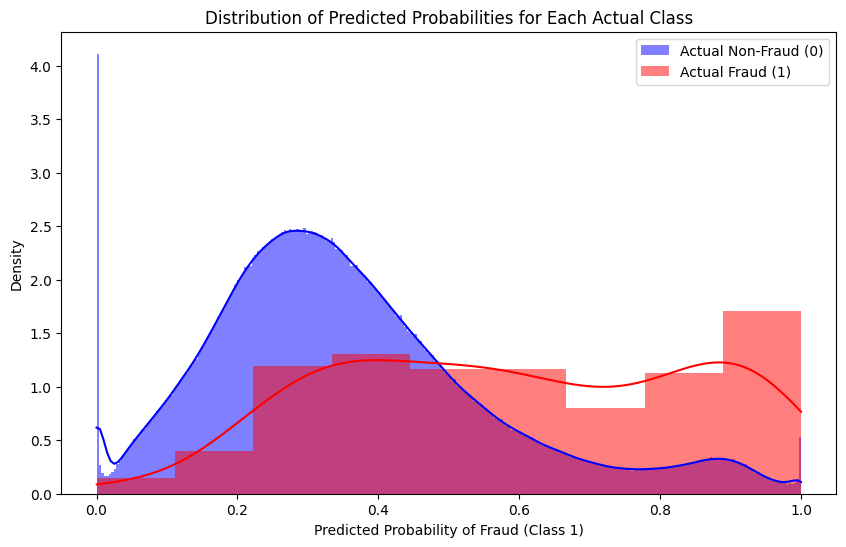

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(
    y_pred_proba_lr_smote[y_test == 0],
    color="blue",
    kde=True,
    stat="density",
    linewidth=0,label="Actual Non-Fraud (0)"
)
sns.histplot(
    y_pred_proba_lr_smote[y_test == 1],
    color="red",
    kde=True,
    stat="density",
    linewidth=0,
    label="Actual Fraud (1)"
)
plt.title("Distribution of Predicted Probabilities for Each Actual Class")
plt.xlabel("Predicted Probability of Fraud (Class 1)")
plt.ylabel("Density")
plt.legend()
plt.show()

# Results

- There is a huge amount of false positives, almost half a million false alarms.
- There are less false negatives than producted by the Random Forest.
- SMOTE worked in the sense that it made the Logistic Regression model much more sensitive to the minority class. Recall for fraud is now `149 / 248 = 60%`, which is a huge improvement from the Random Forests 0%.
- However, this came at a massive cost to precision `149 + (149 + 463738) = 0.03%`. This means that out of all the transactions flagged as potential fraud, only 0.03% actually were fraud.
- `AUC-PR = 0.0005`: The score is so low because the precision is so poor across almost all recall levels.
- `ROC AUC = 0.7620`: Indicates separability but this is masked by the poor precision performance.

While SMOTE successfully forced the model to identify more fraud (higher Recall), it did so by drastically increasing the False Positives. Although this model is unusable due to the amount of false positives, for the sake of brevity, we will use this as our model.

# Save Final Model

In [ ]:
final_pipeline = lr_smote_pipeline
file_path = Path("..", "models", "fraud_detection_pipeline.joblib")
joblib.dump(final_pipeline, file_path)

['../models/fraud_detection_pipeline.joblib']